# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information
**Name: Habibullah**
**Student ID: 023-24-0077**
**Section:D**
**GitHub:**
**Kaggle:**
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [55]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay


---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [56]:
# Task 1 — load spam.csv, inspect shape/head/class balance
spam_df = pd.read_csv("Dataset/spam.csv", encoding = "Latin-1")
print("Shape of spam.csv: ", spam_df.shape)
print("\nFirst five rows of spam.csv:\n ", spam_df.head())
print("\nClass Counts:", spam_df["v1"].value_counts())
print("\nClass percentages:")
print((spam_df["v1"].value_counts(normalize = True) * 100).round(2))

Shape of spam.csv:  (5572, 5)

First five rows of spam.csv:
       v1                                                 v2 Unnamed: 2  \
0   ham  Go until jurong point, crazy.. Available only ...        NaN   
1   ham                      Ok lar... Joking wif u oni...        NaN   
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...        NaN   
3   ham  U dun say so early hor... U c already then say...        NaN   
4   ham  Nah I don't think he goes to usf, he lives aro...        NaN   

  Unnamed: 3 Unnamed: 4  
0        NaN        NaN  
1        NaN        NaN  
2        NaN        NaN  
3        NaN        NaN  
4        NaN        NaN  

Class Counts: v1
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
v1
ham     86.59
spam    13.41
Name: proportion, dtype: float64


In [57]:
# Task 1 (continued) — load Tweets.csv, drop neutral, inspect shape/head/class balance

tweets_df = pd.read_csv("Dataset/Tweets.csv")
print("Shape before drop: ", tweets_df.shape)
print("\nFirst five rows before drop:")
print(tweets_df.head())

tweets_df = tweets_df[tweets_df["airline_sentiment"].isin(["positive", "negative"])].copy()
print("\nShape after removing neutral tweets:", tweets_df.shape)

print("Shape before drop: ", tweets_df.shape)
print("\nFirst five rows before drop:")
print(tweets_df.head())

print("\nRemaining sentiment counts:")
print(tweets_df["airline_sentiment"].value_counts())

print("\nRemaining sentiment percentages:")
print((tweets_df["airline_sentiment"].value_counts(normalize=True) * 100).round(2))

Shape before drop:  (14640, 15)

First five rows before drop:
             tweet_id airline_sentiment  airline_sentiment_confidence  \
0  570306133677760513           neutral                        1.0000   
1  570301130888122368          positive                        0.3486   
2  570301083672813571           neutral                        0.6837   
3  570301031407624196          negative                        1.0000   
4  570300817074462722          negative                        1.0000   

  negativereason  negativereason_confidence         airline  \
0            NaN                        NaN  Virgin America   
1            NaN                     0.0000  Virgin America   
2            NaN                        NaN  Virgin America   
3     Bad Flight                     0.7033  Virgin America   
4     Can't Tell                     1.0000  Virgin America   

  airline_sentiment_gold        name negativereason_gold  retweet_count  \
0                    NaN     cairdin         

**Answer 2 (Task A — spam):**
Each row represents an SMS message labeled as either spam or ham (legitimate). The purpose is to classify incoming messages so that spam can be identified and separated from legitimate messages. This is a binary classification problem because there are two target classes: spam and ham.

**Answer 2 (Task B — sentiment):**
Each row represents a tweet expressing sentiment about an airline. For this lab, neutral tweets are removed, leaving only positive and negative tweets. The goal is to classify the sentiment expressed in a tweet, making this a binary classification problem.

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [58]:
# Task 3 — clean text
spam_df["v2"] = spam_df["v2"].str.lower()

spam_df["v2"] = spam_df["v2"].str.replace(r"[^\w\s]", "", regex = True)

display(spam_df[["v2"]].head())

,v2
0,go until jurong point crazy available only in ...
1,ok lar joking wif u oni
2,free entry in 2 a wkly comp to win fa cup fina...
3,u dun say so early hor u c already then say
4,nah i dont think he goes to usf he lives aroun...


In [59]:
# Task 4 — encode labels, split, fit vectorizer on train only, transform both sets

spam_df["v1"] = spam_df["v1"].map({
    "ham": 0, "spam": 1
})

X = spam_df["v2"]
y = spam_df["v1"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

vectorizer = CountVectorizer()

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print("Training data shape:", X_train_vec.shape)
print("Testing data shape:", X_test_vec.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

Training data shape: (4457, 8414)
Testing data shape: (1115, 8414)
Vocabulary size: 8414


**Answer 4 (why fit on training data only):**
The vectorizer must be fitted only on the training messages to prevent data leakage from the test set. The same fitted vocabulary is then used to transform both training and testing messages, ensuring that the model is evaluated on unseen data without learning preprocessing information from the test set.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

Accuracy:  0.9820627802690582
Precision:  0.9850746268656716
Recall:  0.88
F1-score:  0.9295774647887324


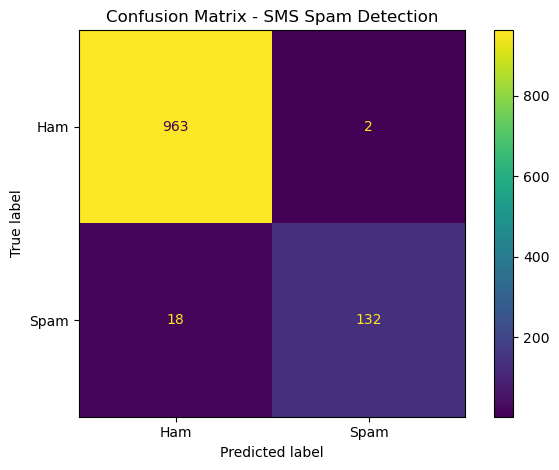

In [60]:
# Task 5 — train MultinomialNB, compute metrics, plot confusion matrix

model = MultinomialNB()
model.fit(X_train_vec, y_train)

y_pred = model.predict(X_test_vec)

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1-score: ", f1_score(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix = cm,
                             display_labels = ["Ham", "Spam"])

disp.plot()
plt.title("Confusion Matrix - SMS Spam Detection")
plt.tight_layout()
plt.show()

**Task 5 — Spam Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 98.2%|
| Precision | 98.5%|
| Recall | 88%|
| F1-score | 92.9%|

**Answer 6:**
A false positive hides a legitimate message as spam, while a false negative allows spam into the inbox. I would prioritize precision to avoid hiding important messages. My model achieved 98.51% precision and 88% recall, indicating that some spam messages are still missed.

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [61]:
# Task 7 — extract top spam words and top ham words from feature_log_prob_

words = vectorizer.get_feature_names_out()
log_probs = model.feature_log_prob_

ham_idx = list(model.classes_).index(0)
spam_idx = list(model.classes_).index(1)

difference = log_probs[spam_idx] - log_probs[ham_idx]

spam_indices = np.argsort(difference)[-15:][::-1]
ham_indices = np.argsort(difference)[:15]

print("Top 15 words associated with spam:")
print(words[spam_indices])

print("\nTop 15 words associated with ham:")
print(words[ham_indices])

Top 15 words associated with spam:
['claim' 'prize' 'won' 'tone' 'guaranteed' '18' '150ppm' 'awarded' 'å1000'
 'å2000' 'tcs' 'entry' 'ringtone' 'å150' 'tones']

Top 15 words associated with ham:
['ltgt' 'ill' 'he' 'lor' 'da' 'she' 'later' 'ì_' 'too' 'my' 'thats' 'say'
 'ask' 'said' 'amp']


**Answer 7:**
The words most associated with spam have higher log-probabilities for the spam class than for ham. Words most associated with ham have higher log-probabilities for legitimate messages. These results help explain which words influence the classifier's predictions.

In [62]:
# Task 8 — test your own messages
my_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting for lunch today?"
]

cleaned_messages = [msg.lower() for msg in my_messages]

test_vectors = vectorizer.transform(cleaned_messages)
predictions = model.predict(test_vectors)

for message, prediction in zip(my_messages, predictions):
    label = "Spam" if prediction == 1 else "Ham"
    print(f"Message: {message}")
    print(f"Prediction: {label}\n")

Message: Congratulations! You have won a free prize. Claim now!
Prediction: Spam

Message: Hey, are we meeting for lunch today?
Prediction: Ham



**Answer 8:**
The spam-like messages are expected to be classified as spam, while the ordinary lunch message is expected to be classified as ham. Actual predictions depend on the words learned during training and should be checked from the output.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [67]:
# Task 11 — clean and vectorize the sentiment data (your own approach)

tweets_df = tweets_df[tweets_df["airline_sentiment"].isin(["positive", "negative"])].copy()

tweets_df["text"] = tweets_df["text"].str.lower()
tweets_df["text"] = tweets_df["text"].str.replace(r"@\w+", "", regex=True)

tweets_df["text"] = tweets_df["text"].str.replace(r"http\S+|www\.\S+", "", regex=True)
tweets_df["text"] = tweets_df["text"].str.strip()

tweets_df["label"] = tweets_df["airline_sentiment"].map({
    "negative": 0,
    "positive": 1
})

X_tweet = tweets_df["text"]
y_tweet = tweets_df["label"]

X_train_tweet, X_test_tweet, y_train_tweet, y_test_tweet = train_test_split(
    X_tweet, y_tweet, test_size = 0.2, random_state = 42, stratify = y_tweet
)

tweet_vectorizer = CountVectorizer()
X_train_tweet_vec = tweet_vectorizer.fit_transform(X_train_tweet)
X_test_tweet_vec = tweet_vectorizer.transform(X_test_tweet)


print("Training data shape:", X_train_tweet_vec.shape)
print("Testing data shape:", X_test_tweet_vec.shape)
print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))

Training data shape: (9232, 10083)
Testing data shape: (2309, 10083)
Vocabulary size: 10083


**Answer 12:**
I converted tweets to lowercase and removed @mentions and URLs because they may add noise and create unnecessary features. Tweets contain more social-media-specific content than SMS messages, so this cleaning helps the model focus more on words that express sentiment.

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

Accuracy: 0.9034213945430922
Precision: 0.9084967320261438
Recall: 0.587737843551797
F1-score: 0.7137355584082157


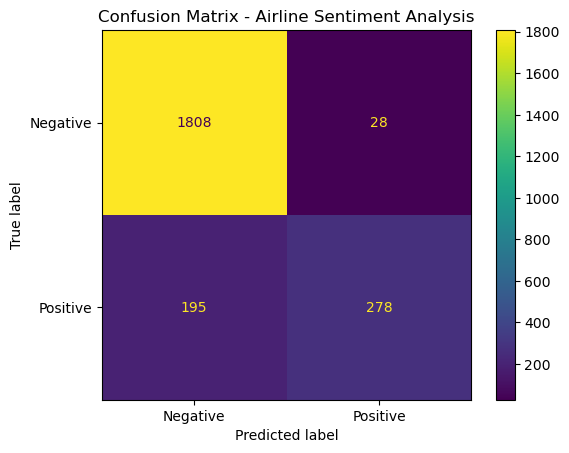

In [68]:
# Task 13 — train MultinomialNB, compute metrics, plot confusion matrix

model_tweet = MultinomialNB()

model_tweet.fit(X_train_tweet_vec, y_train_tweet)

y_pred_tweet = model_tweet.predict(X_test_tweet_vec)

print("Accuracy:", accuracy_score(y_test_tweet, y_pred_tweet))
print("Precision:", precision_score(y_test_tweet, y_pred_tweet))
print("Recall:", recall_score(y_test_tweet, y_pred_tweet))
print("F1-score:", f1_score(y_test_tweet, y_pred_tweet))

cm = confusion_matrix(y_test_tweet, y_pred_tweet)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Confusion Matrix - Airline Sentiment Analysis")
plt.show()

**Task 13 — Sentiment Model Metrics**

| Metric | Value |
|---|---|
| Accuracy | 90.3%|
| Precision | 90.8%|
| Recall | 58.8%|
| F1-score | 71.4%|

**Answer 14:**
Naive Bayes may perform better on spam detection because spam messages use predictable words. Tweets are harder to classify due to sarcasm, negation, and context. Therefore, the independence assumption is less suitable for sentiment analysis. Compare the actual metrics from Tasks 5 and 13 to determine which performed better.

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(paste your published notebook link here)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 98.2%| 90.3%|
| Precision | 98.5%| 90.8%|
| Recall | 88%| 58.8%|
| F1-score | 92.9%| 71.4%|

In [69]:
# Task 17 - Comapre Navie Bayes - Spam vs Sentiment

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Task A - Spam Detection": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    "Task B - Sentiment Analysis": [
        accuracy_score(y_test_tweet, y_pred_tweet),
        precision_score(y_test_tweet, y_pred_tweet),
        recall_score(y_test_tweet, y_pred_tweet),
        f1_score(y_test_tweet, y_pred_tweet)
    ]
})

print(comparison.to_string(index=False))

   Metric  Task A - Spam Detection  Task B - Sentiment Analysis
 Accuracy                 0.982063                     0.903421
Precision                 0.985075                     0.908497
   Recall                 0.880000                     0.587738
 F1-Score                 0.929577                     0.713736


In [70]:
# Task 18 — train Logistic Regression on Task A's vectorized features

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vec, y_train)

y_pred_lr = lr_model.predict(X_test_vec)

comparison_lr = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Naive Bayes": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr)
    ]
})

print(comparison_lr.to_string(index=False))

   Metric  Naive Bayes  Logistic Regression
 Accuracy     0.982063             0.978475
Precision     0.985075             0.992188
   Recall     0.880000             0.846667
 F1-Score     0.929577             0.913669


**Task 18 — Naive Bayes vs. Logistic Regression (Task A)**

| Metric | Naive Bayes | Logistic Regression |
|---|---|---|
| Accuracy | 98.2%| 97.8%|
| Precision | 98.5%| 99.2%|
| Recall | 88%| 84.7%|
| F1-score | 92.9%| 91.4%|

**Answer 18 (which wins, and does it match expectations):**
Logistic Regression and Naive Bayes are compared using accuracy, precision, recall, and F1-score on the same SMS features. The model with better evaluation metrics performs better on this dataset. Logistic Regression may perform better because it does not assume that words are conditionally independent given the class. The final winner depends on the actual results obtained from both models.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
Naive Bayes performed well on spam detection because spam messages often contain predictable words. In sentiment analysis, tweets were harder to classify because of sarcasm, negation, and context. The most predictive spam words helped explain how the model distinguishes spam from legitimate messages. Logistic Regression and Naive Bayes were compared using accuracy, precision, recall, and F1-score. The model with better evaluation metrics performed better on the SMS dataset. The independence assumption is a limitation because the meaning of words can depend on other words in a sentence. Overall, this lab demonstrated how Naive Bayes can be applied to two different text-classification problems.

**Answer 20 — Kaggle Notebook Links:**
- Task A: _______
- Task B: _______

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, both datasets)
- [ ] Section 1 — Problem Definition & Dataset Exploration (both datasets, neutral tweets dropped)
- [ ] Section 2 — Task A Cleaning & Vectorization (fit on training data only)
- [ ] Section 3 — Task A Model & Evaluation (all four metrics + confusion matrix + precision/recall argument)
- [ ] Section 4 — Task A Word Interpretation (top words + your own test messages)
- [ ] Section 5 — Task A Kaggle Notebook published and linked
- [ ] Section 6 — Task B Cleaning & Vectorization (cleaning choices justified)
- [ ] Section 7 — Task B Model & Evaluation (all four metrics + independence-assumption discussion)
- [ ] Section 8 — Task B Kaggle Notebook published and linked
- [ ] Section 9 — Cross-Task Comparison & vs. Logistic Regression
- [ ] Section 10 — Final Reflection & Conclusion (both Kaggle links listed again)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted